# Model Selection and Hyperparameter Tuning

**Use scikit-learn as much as possible!**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

## Ames Housing Data

As usual, we'll try to predict SalePrice using a mix of quantitative and categorical features. See the [data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for all the variables that are available in the data set. We'll try to come up with a model that minimizes test error, measured by root mean square error (RMSE).

In [2]:
df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


1\. Recall that in a previous notebook we fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. But what about other sets of features?

Specify 5 sets of features to investigate. These sets could be subsets of the variables above, but you should also include other variables from the data set. The choice is up to you, but try to guess which sets might lead to good models based on your intuition and what we have already seen for this data set.

For each set of features, fit a 10-nearest neighbors regression model and estimate its test error (RMSE) using cross-validation. You can write a loop to iterate over the sets of features similar to what was done in the Model Selection section of the pre-class notebook.

Report your lowest RMSE and the corresponding features.

In [3]:
y = df_ames["SalePrice"]

folds = KFold(n_splits= 5, shuffle=True, random_state=5544)     # the same 5 folds for every candidate

def preprocessing(numeric, categorical=(), scale=True):
    """Impute + (optionally) scale the numeric columns; one-hot encode the categorical ones."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    transformers = [("num", Pipeline(numeric_steps), list(numeric))]
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), list(categorical)))
    return ColumnTransformer(transformers)

def cv_rmse(model, columns):
    """Cross-validated test RMSE (dollars) of a model on the given columns, on the shared folds."""
    scores = cross_val_score(model, df_ames[columns], y, cv=folds, scoring="neg_root_mean_squared_error")
    return -scores.mean()

print(df_ames.shape)

(2930, 82)


In [4]:
feature_sets = {
    "size only":                             (["Gr Liv Area"], []),
    "size + quality":                        (["Gr Liv Area", "Overall Qual"], []),
    "size + quality + lot":                 (["Gr Liv Area", "Overall Qual", "Lot Area"], []),
    "size + quality + lot + year":          (["Gr Liv Area", "Overall Qual", "Lot Area", "Year Built"], []),
    "size + quality + lot + Neighborhood":  (["Gr Liv Area", "Overall Qual", "Lot Area"], ["Neighborhood"]),
    "size + quality + lot + full_bath + year + Neighborhood":  (["Gr Liv Area", "Overall Qual", "Lot Area", "Full Bath", "Year Built"], ["Neighborhood"]),
}

results = {}
for name, (numeric, categorical) in feature_sets.items():
    pipe = Pipeline([("prep", preprocessing(numeric, categorical)),
                     ("knn", KNeighborsRegressor(n_neighbors=10))])
    results[name] = cv_rmse(pipe, numeric + categorical)

pd.Series(results, name="CV test RMSE (10-NN)").round(0).to_frame()

,CV test RMSE (10-NN)
size only,57893.0
size + quality,36549.0
size + quality + lot,35398.0
size + quality + lot + year,32171.0
size + quality + lot + Neighborhood,33169.0
size + quality + lot + full_bath + year + Neighborhood,32262.0


2\. Recall that in a previous notebook we fit a $k$-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Previously we used a loop to iterate and find the value of $k$ with the smallest test error (RMSE).

Now use grid search in scikit-learn to implement this process. Use the results to create a plot of test error versus $k$.

In [5]:
numeric, categorical = feature_sets["size + quality + lot + year"]
columns = numeric + categorical

by_hand = {}
for k in [1, 3, 5, 10, 20, 50]:
    pipe = Pipeline([("prep", preprocessing(numeric, categorical)),
                     ("knn", KNeighborsRegressor(n_neighbors=k))])
    by_hand[k] = cv_rmse(pipe, columns)

pd.Series(by_hand, name="CV test RMSE").round(0).to_frame()

,CV test RMSE
1,39294.0
3,34271.0
5,33426.0
10,32171.0
20,32928.0
50,33301.0


In [6]:
pipe = Pipeline([("prep", preprocessing(numeric, categorical)),
                 ("knn", KNeighborsRegressor())])            # no k yet: the grid supplies it

param_grid = {"knn__n_neighbors": range(1, 26)}

grid = GridSearchCV(pipe, param_grid, cv=folds, scoring="neg_root_mean_squared_error")
grid.fit(df_ames[columns], y)

print("best parameters:", grid.best_params_)
print("best CV test RMSE:", round(-grid.best_score_))

best parameters: {'knn__n_neighbors': 11}
best CV test RMSE: 32094


In [7]:
cv_table = pd.DataFrame(grid.cv_results_)
cv_table["CV test RMSE"] = -cv_table["mean_test_score"]
cv_table[["param_knn__n_neighbors", "CV test RMSE", "std_test_score", "rank_test_score"]].round(0).head(12)

,param_knn__n_neighbors,CV test RMSE,std_test_score,rank_test_score
0,1,39294.0,2732.0,25
1,2,34524.0,1955.0,24
2,3,34271.0,2242.0,22
3,4,34382.0,2556.0,23
4,5,33426.0,2837.0,21
5,6,32999.0,2899.0,20
6,7,32743.0,2814.0,11
7,8,32477.0,2746.0,5
8,9,32317.0,2997.0,3
9,10,32171.0,3021.0,2


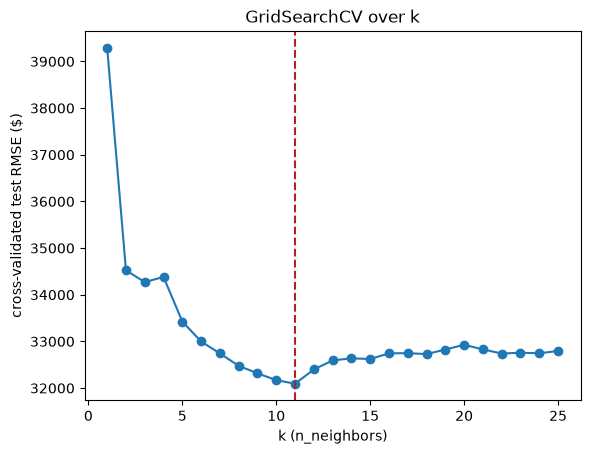

In [8]:
ax = cv_table.plot(x="param_knn__n_neighbors", y="CV test RMSE", marker="o", legend=False)
ax.axvline(grid.best_params_["knn__n_neighbors"], color="firebrick", linestyle="--")
ax.set_xlabel("k (n_neighbors)"); ax.set_ylabel("cross-validated test RMSE ($)")
ax.set_title("GridSearchCV over k");

3\. $k$-nearest neighbors relies on distance and we know there are different distance metrics. Repeat the previous part and use grid search to iterate over both (1) `n_neighbors` and (2) `metric`, which can be `"euclidean"` or `"manhattan"` (see the the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)). Compare the results to the previous part. (Hint: recall the note in the pre-class notebook about grid search conventions for refering to steps in the pipeline.)

In [9]:
# Search over both k and the distance metric.
param_grid_2 = {
    "knn__n_neighbors": range(1, 26),
    "knn__metric": ["euclidean", "manhattan"]
}

grid2 = GridSearchCV(pipe, param_grid_2, cv=folds,
                     scoring="neg_root_mean_squared_error")
grid2.fit(df_ames[columns], y)

print("Question 3 best parameters:", grid2.best_params_)
print("Question 3 CV test RMSE: $", round(-grid2.best_score_))
print("This is slightly better than the search over k alone.")

Question 3 best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 14}
Question 3 CV test RMSE: $ 31600
This is slightly better than the search over k alone.


4\. Combine elements of the previous parts and fit what you think will be the best $k$-nearest neighbors model. Specify which features you are using, the value of $k$, and the distance metric. Estimate the test error. (In 2-3 you used the specified set of features. Now you can combine elements of 2-3 with the features you chose in part 1, or other sets of features, as well as investigating other parameter choices.)

Note: Look at the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) for a full list of parameters. You might consider tuning `n_neighbors`, `metric` (or `p`), and/or `weights`. You could also try other elements like scaling too.

In [10]:
# Use the strongest feature set from Question 1 and also tune the weights.
best_features = "size + quality + lot + full_bath + year + Neighborhood"
numeric_best, categorical_best = feature_sets[best_features]
columns_best = numeric_best + categorical_best

knn_best_pipe = Pipeline([
    ("prep", preprocessing(numeric_best, categorical_best)),
    ("knn", KNeighborsRegressor())
])

param_grid_best = {
    "knn__n_neighbors": range(1, 26),
    "knn__metric": ["euclidean", "manhattan"],
    "knn__weights": ["uniform", "distance"]
}

grid_best_knn = GridSearchCV(knn_best_pipe, param_grid_best, cv=folds,
                              scoring="neg_root_mean_squared_error")
grid_best_knn.fit(df_ames[columns_best], y)
knn_rmse = -grid_best_knn.best_score_

print("Question 4 features:", columns_best)
print("Question 4 best parameters:", grid_best_knn.best_params_)
print("Question 4 CV test RMSE: $", round(knn_rmse))

Question 4 features: ['Gr Liv Area', 'Overall Qual', 'Lot Area', 'Full Bath', 'Year Built', 'Neighborhood']
Question 4 best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}
Question 4 CV test RMSE: $ 30466


5\. Now fit a linear regression model using the same features that you used in the previous part. Estimate the test error. How does the test error for linear regression compare to the kNN model?


In [11]:
linear_pipe = Pipeline([
    ("prep", preprocessing(numeric_best, categorical_best)),
    ("linear", LinearRegression())
])

linear_scores = cross_val_score(
    linear_pipe, df_ames[columns_best], y, cv=folds,
    scoring="neg_root_mean_squared_error"
)
linear_rmse = -linear_scores.mean()

print("Question 5 linear regression CV test RMSE: $", round(linear_rmse))
print("Linear regression is $", round(linear_rmse - knn_rmse),
      "worse than the tuned KNN model.")

Question 5 linear regression CV test RMSE: $ 34992
Linear regression is $ 4527 worse than the tuned KNN model.


## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

Note: when you are consider features to include, you might want to consider transformations of the variables.

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [12]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


Data shape: (10000, 56)


count    10000.00
mean        12.43
std          5.00
min          5.31
25%          9.43
50%         11.98
75%         15.05
max         30.94
Name: interest_rate, dtype: float64

,count,mean
sub_grade,,
A1,422,5.32
A2,480,6.08
A3,504,6.72
A4,568,7.35
A5,485,7.97
B1,647,9.44
B2,638,9.93
B3,540,10.42
B4,581,10.91


,interest_rate
issue_month,
Feb-2018,12.51
Jan-2018,12.38
Mar-2018,12.41


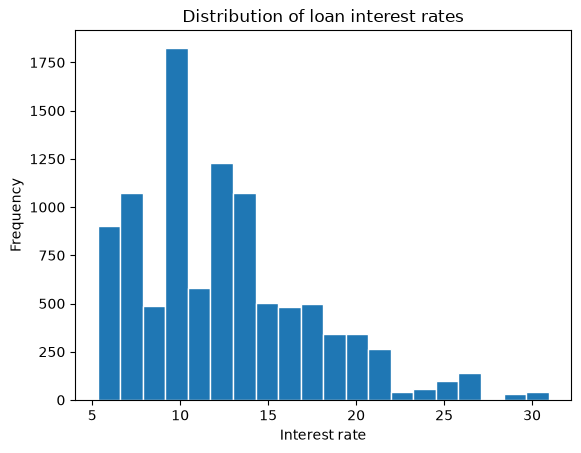

,CV test RMSE
decision tree {'model__max_depth': None},0.121
linear regression,0.188
"KNN {'model__n_neighbors': 50, 'model__weights': 'distance'}",0.461


Best loans model: decision tree {'model__max_depth': None}
Best loans CV test RMSE: 0.121


In [13]:
# Explore the response and two useful categorical predictors.
print("Data shape:", df.shape)
display(df["interest_rate"].describe().round(2))
display(df.groupby("sub_grade")["interest_rate"].agg(["count", "mean"]).round(2))
display(df.groupby("issue_month")["interest_rate"].mean().round(2).to_frame())

df["interest_rate"].plot.hist(bins=20, edgecolor="white")
plt.xlabel("Interest rate")
plt.title("Distribution of loan interest rates")
plt.show()

# Keep the model simple and avoid post-loan variables such as paid_interest.
loan_features = ["sub_grade", "issue_month"]
X_loans = df[loan_features]
y_loans = df["interest_rate"]
loan_folds = KFold(n_splits=5, shuffle=True, random_state=5544)

loan_prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), loan_features)
])

# Model 1: linear regression (no tuning needed).
loan_linear = Pipeline([
    ("prep", loan_prep),
    ("model", LinearRegression())
])
linear_loan_rmse = -cross_val_score(
    loan_linear, X_loans, y_loans, cv=loan_folds,
    scoring="neg_root_mean_squared_error"
).mean()

# Model 2: tune k and weights for KNN.
loan_knn = Pipeline([
    ("prep", loan_prep),
    ("model", KNeighborsRegressor())
])
loan_knn_grid = GridSearchCV(
    loan_knn,
    {"model__n_neighbors": [5, 10, 25, 50],
     "model__weights": ["uniform", "distance"]},
    cv=loan_folds, scoring="neg_root_mean_squared_error"
).fit(X_loans, y_loans)

# Model 3: tune the depth of a decision tree.
loan_tree = Pipeline([
    ("prep", loan_prep),
    ("model", DecisionTreeRegressor(random_state=5544))
])
loan_tree_grid = GridSearchCV(
    loan_tree,
    {"model__max_depth": [3, 5, 7, 9, None]},
    cv=loan_folds, scoring="neg_root_mean_squared_error"
).fit(X_loans, y_loans)

loan_results = pd.Series({
    "linear regression": linear_loan_rmse,
    f"KNN {loan_knn_grid.best_params_}": -loan_knn_grid.best_score_,
    f"decision tree {loan_tree_grid.best_params_}": -loan_tree_grid.best_score_
}, name="CV test RMSE").sort_values()

display(loan_results.round(3).to_frame())
print("Best loans model:", loan_results.index[0])
print("Best loans CV test RMSE:", round(loan_results.iloc[0], 3))